# Milestone 4: Target network and experience replay on CarRacing

**Goal:** add the two improvements from the course to the milestone-3 agent and compare. Everything else is identical: same pixels, network, reward scaling, 50,000-step budget and seeds.

- **Experience replay:** store transitions in a 20,000-slot buffer and learn from random mini-batches of 32 (one update every 4 steps).
- **Target network:** bootstrap from a frozen copy of the network, synced every 1,000 steps.

Code: `src/carracing.py` (variant `dqn`), runs launched by `experiments/run_carracing.py`.

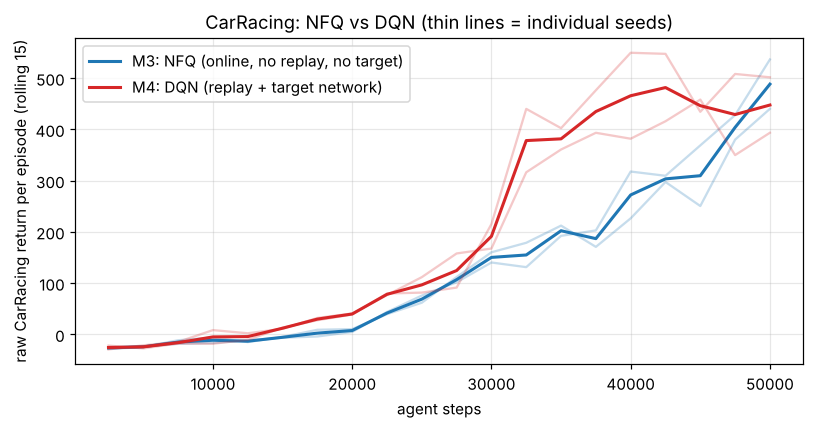

In [1]:
import sys, json, glob; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, gymnasium as gym, torch
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
from src import carracing as C
def load(variant):
    return [json.load(open(p)) for p in sorted(glob.glob(f"../results/car_{variant}_s*.json"))]
def smooth(hist, grid, window=15):
    st = np.array([h[0] for h in hist]); rt = np.array([h[1] for h in hist]); out = []
    for g in grid:
        idx = np.where(st <= g)[0][-window:]; out.append(rt[idx].mean() if len(idx) else np.nan)
    return np.array(out)
nfq, dqn = load("nfq"), load("dqn"); grid = np.arange(2_500, 50_001, 2_500)
fig, ax = plt.subplots(figsize=(7.5, 4))
for name, rs, col in [("M3: NFQ (online, no replay, no target)", nfq, "tab:blue"), ("M4: DQN (replay + target network)", dqn, "tab:red")]:
    cs = np.array([smooth(r["hist"], grid) for r in rs]); m = np.nanmean(cs, 0)
    for c in cs: ax.plot(grid, c, c=col, alpha=.25)
    ax.plot(grid, m, c=col, lw=2, label=name)
ax.set(xlabel="agent steps", ylabel="raw CarRacing return per episode (rolling 15)", title="CarRacing: NFQ vs DQN (thin lines = individual seeds)")
ax.legend(); plt.tight_layout(); plt.savefig("../docs/img/m4_comparison.png"); plt.show()

## Greedy evaluation: 10 unseen tracks per run

In [2]:
rows = []
for name, rs in [("NFQ", nfq), ("DQN", dqn)]:
    for r in rs: rows.append(dict(method=name, seed=r["seed"], mean_return=np.mean(r["eval"]), std=np.std(r["eval"]), best_episode=np.max(r["eval"]), minutes=r["minutes"]))
tab = pd.DataFrame(rows).round(1); print(tab.to_string(index=False))
print("\nmean over seeds:\n", tab.groupby("method")[["mean_return", "best_episode"]].mean().round(1).to_string())
rnd = [r["random_eval"] for r in nfq if r["random_eval"]]
if rnd: print("\nrandom policy (10 episodes): mean", round(np.mean(rnd[0]), 1))
tab.to_csv("../results/car_comparison.csv", index=False)

method  seed  mean_return   std  best_episode  minutes
   NFQ     0        -19.9   0.3         -19.0     30.4
   NFQ     1        508.0 119.6         646.9     28.7
   DQN     0        347.5 155.9         568.1     28.7
   DQN     1        405.6 194.9         739.4     26.2

mean over seeds:
         mean_return  best_episode
method                           
DQN           376.6         653.8
NFQ           244.0         314.0

random policy (10 episodes): mean -28.7


## Same agents with 5% random actions (as in the training curve)

In [3]:
import random
rows = []
for name, rs in [("NFQ", nfq), ("DQN", dqn)]:
    for r in rs:
        qn = C.QCNN(); qn.load_state_dict(torch.load(f"../models/car_{name.lower()}_s{r['seed']}.pt")); qn.eval(); random.seed(0)
        noisy = C.evaluate(qn, episodes=5, policy=lambda s: random.randrange(5) if random.random() < 0.05 else C.act_greedy(qn, s))
        rows.append(dict(method=name, seed=r["seed"], greedy_mean_10=np.mean(r["eval"]), noisy_mean_5=np.mean(noisy), noisy_worst_of_5=np.min(noisy)))
noise = pd.DataFrame(rows).round(1); print(noise.to_string(index=False)); noise.to_csv("../results/car_noise_eval.csv", index=False)

method  seed  greedy_mean_10  noisy_mean_5  noisy_worst_of_5
   NFQ     0           -19.9         293.7             -20.0
   NFQ     1           508.0         481.0             328.2
   DQN     0           347.5         259.6               9.6
   DQN     1           405.6         405.4             101.7


## One greedy episode of the best DQN agent

In [4]:
import imageio.v2 as imageio
best = max(dqn, key=lambda r: np.mean(r["eval"]))
qn = C.QCNN(); qn.load_state_dict(torch.load(f"../models/car_dqn_s{best['seed']}.pt")); qn.eval()
e = C.CarEnv(render=True); s = e.reset(seed=900_000); done = False; frames = [e.env.render()]
while not done:
    s, r, done = e.step(C.act_greedy(qn, s)); frames.append(e.env.render())
imageio.mimsave("../docs/img/m4_dqn_episode.gif", frames, duration=0.08, loop=0)
print(f"seed {best['seed']}: {len(frames)-1} agent steps, raw return {e.raw_return:.1f}")

seed 1: 238 agent steps, raw return 739.4


## Takeaways
- **Replay + target network learned faster.** Rolling training return at 32,500 steps: **378 for DQN vs 155 for NFQ** (mean of 2 seeds); at 40,000 steps 466 vs 272. NFQ caught up by the end of the budget (488 vs 448 at 50,000 steps).
- **Greedy evaluation (10 unseen tracks per run):** DQN **347.5 and 405.6** (mean 376.6); NFQ **-19.9 and 508.0** (mean 244.0). DQN produced two working policies; NFQ produced the best policy and a collapsed one.
- **Honest reading:** the improvements gave faster, steadier learning and removed the collapsed seed here, but not a higher final score. The mean gap is driven by one NFQ seed, and with 2 seeds per method I would not claim a significant difference. Replay and the target network were not separated in this milestone (see notebook m5b for that ablation in the warehouse).
- With 5% random actions DQN scored 260 and 405 (worst of five tracks: 10 and 102), so DQN's weakest tracks were poor but not total failures. Best single episode overall: 739 (DQN seed 1).